# BTCUSDT 15m trend prediction — test suite (T01–T13)

Runs the whole automated acceptance suite and shows the evidence it produced:
the pytest verdict for each case **T01–T13**, the pass/fail table, the run log
and the screenshots the dashboard tests captured.

Everything this notebook writes stays inside `tests/`:

| artefact | path |
| --- | --- |
| full run log — timestamped, per test, per case, then the whole console transcript | `tests/logs/test_run.log` |
| machine-readable results — one verdict per case T01–T13 | `tests/logs/results.json` |
| panel renders, page dumps and PNGs | `tests/screenshots/` |

**To run it**: *Kernel → Restart & Run All*. The suite takes roughly 70 seconds,
most of it the three browser/server cases (T06, T08, T12).

The same suite from a terminal:

```
python tests/run_tests.py          # run, then print the T01-T13 table
pytest tests -v                    # the tests alone; conftest still writes the logs
python tests/run_tests.py -k T11   # extra arguments go straight to pytest
```


## 0. Setup — locate the project, import the runner

Works whether Jupyter was started in `tests/` or in the project root.

In [1]:
import json
import os
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name == "tests" else HERE
TESTS_DIR = PROJECT_ROOT / "tests"

os.chdir(PROJECT_ROOT)                      # so `!pytest tests -v` works too
if str(TESTS_DIR) not in sys.path:
    sys.path.insert(0, str(TESTS_DIR))

import _support     # paths, evidence writers, the T01-T13 case table
import run_tests    # the runner the terminal uses

import pandas as pd

print("project root :", PROJECT_ROOT)
print("python       :", sys.version.split()[0])
print("node         :", _support.node_exe() or "not found (T13 will report BLOCKED)")
print()
print("log          :", _support.RUN_LOG)
print("results      :", _support.RESULTS_JSON)
print("screenshots  :", _support.SCREENSHOTS_DIR)

project root : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction
python       : 3.13.12
node         : C:\Program Files\nodejs\node.EXE

log          : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\logs\test_run.log
results      : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\logs\results.json
screenshots  : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\screenshots


## 1. Run the T01–T13 suite

`run_tests.run()` spawns `python -m pytest tests -v` in a child process — the same command the terminal uses, with the same interpreter. The child's stdout and stderr are echoed below as they arrive, and are returned as one transcript so the next cell can append them to the log file.

In [ ]:
exit_code, transcript = run_tests.run(verbose=True, write_report=True)

print()
print("pytest exit code:", exit_code, "(0 = every test passed)")

ACCEPTANCE TEST RUN - T01..T13
started        : 2026-10-07T22:15:43+05:30
command        : C:\Users\ushan\miniconda3\python.exe -m pytest E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests -v
python         : 3.13.12  (C:\Users\ushan\miniconda3\python.exe)
node           : C:\Program Files\nodejs\node.EXE
project root   : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction
pytest args    : (none)
============================= test session starts =============================
platform win32 -- Python 3.13.12, pytest-9.1.1, pluggy-1.5.0 -- C:\Users\ushan\miniconda3\python.exe
cachedir: .pytest_cache
acceptance suite: T01-T13   project root: E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction
python: 3.13.12   node: C:\Program Files\nodejs\node.EXE   reports: results.json, test_run.log
rootdir: E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction
plugins: anyio-4.10.0
collecting ... collected 91 items

tests/test_api.py::test_T06_every_read_endpoi

## 2. The T01–T13 summary

`run_tests.report()` appends the transcript to `tests/logs/test_run.log` and prints the table that was written into it. The same numbers are displayed below as a frame.

In [3]:
results = run_tests.report(transcript)

totals = results["totals"]
headline = (f'### {totals["cases_passed"]} / 13 cases PASS'
            f' — {totals["n_tests"]} tests, {totals["passed"]} passed, '
            f'{totals["failed"]} failed, {totals["errors"]} errors, '
            f'{totals["skipped"]} skipped')
if totals["cases_failed"] or totals["cases_blocked"] or totals["cases_partial"]:
    headline += (f'\n\n> **{totals["cases_failed"]} FAIL, '
                 f'{totals["cases_blocked"]} BLOCKED, '
                 f'{totals["cases_partial"]} PARTIAL** — see the detail below.')
display(Markdown(headline))

pd.DataFrame([
    {
        "case": c["id"],
        "status": c["status"],
        "tests": c["n_tests"],
        "passed": c["n_passed"],
        "failed": c["n_failed"],
        "skipped": c["n_skipped"],
        "seconds": c["duration_seconds"],
        "what it checks": c["title"],
    }
    for c in results["test_cases"]
])


ACCEPTANCE SUITE - T01..T13
ID    STATUS       #     sec  TITLE
------------------------------------------------------------------------------
T01   PASS         3    0.21  Leakage - corrupt every row after row 2,000, recompu
T02   PASS         4    0.47  Leakage - corrupt validation/test rows and refit the
T03   PASS         6    0.27  Windows - every generated window checked for gap cro
T04   PASS         6    0.46  Split - chronological ordering and purge boundaries 
T05   PASS         4   19.98  Audit - all 24 existing data-quality/audit checks pa
T06   PASS        14   16.67  API - snapshot, candles, prediction, track-record an
T07   PASS        18    0.17  API - candles?limit=5 returns HTTP 422 (minimum limi
T08   PASS         5   15.15  API - event stream opens and emits parseable snapsho
T09   PASS         7    0.45  Store - recording the exact same window twice create
T10   PASS         5    0.22  Store - opened read-only, a write is refused and the
T11   PASS         7    0.

### 13 / 13 cases PASS — 91 tests, 91 passed, 0 failed, 0 errors, 0 skipped

,case,status,tests,passed,failed,skipped,seconds,what it checks
0,T01,PASS,3,3,0,0,0.212,"Leakage - corrupt every row after row 2,000, r..."
1,T02,PASS,4,4,0,0,0.467,Leakage - corrupt validation/test rows and ref...
2,T03,PASS,6,6,0,0,0.268,Windows - every generated window checked for g...
3,T04,PASS,6,6,0,0,0.461,Split - chronological ordering and purge bound...
4,T05,PASS,4,4,0,0,19.985,Audit - all 24 existing data-quality/audit che...
5,T06,PASS,14,14,0,0,16.672,"API - snapshot, candles, prediction, track-rec..."
6,T07,PASS,18,18,0,0,0.170,API - candles?limit=5 returns HTTP 422 (minimu...
7,T08,PASS,5,5,0,0,15.153,API - event stream opens and emits parseable s...
8,T09,PASS,7,7,0,0,0.453,Store - recording the exact same window twice ...
9,T10,PASS,5,5,0,0,0.223,"Store - opened read-only, a write is refused a..."


## 3. Each case, and what it ran

In [4]:
rows = "\n".join(
    f'| **{c["id"]}** | **{c["status"]}** | {c["duration_seconds"]:.2f}s '
    f'| {c["title"]} |'
    for c in results["test_cases"]
)
display(Markdown(
    "| case | verdict | time | what it checks |\n|---|---|---|---|\n" + rows))

# Anything that is not a clean pass gets its reason shown verbatim: a BLOCKED
# case is a real outcome here, not something to hide behind a summary table.
problems = [(c, t) for c in results["test_cases"] for t in c["tests"]
            if t["outcome"] != "passed"]
if problems:
    display(Markdown("### Cases that did not pass"))
    for c, t in problems:
        reason = t["skip_reason"] or t["message"] or "(no reason recorded)"
        display(Markdown(f'**{c["id"]} — {t["outcome"]}** — `{t["nodeid"]}`\n\n'
                         f'```\n{reason[:1500]}\n```'))
else:
    display(Markdown(
        f'All {totals["n_tests"]} tests passed; nothing was skipped, '
        "blocked or left partial."))

# Every test in the suite, grouped by case.
for c in results["test_cases"]:
    print(f'--- {c["id"]}  ({c["status"]}) ---')
    for t in c["tests"]:
        print(f'   {t["outcome"]:<8} {t["nodeid"]}')
    print()

| case | verdict | time | what it checks |
|---|---|---|---|
| **T01** | **PASS** | 0.21s | Leakage - corrupt every row after row 2,000, recompute features; earlier features unchanged (maximum difference = 0) |
| **T02** | **PASS** | 0.47s | Leakage - corrupt validation/test rows and refit the scaler; identical mean and scale |
| **T03** | **PASS** | 0.27s | Windows - every generated window checked for gap crossing (expected 0 crossings; total windows checked reported) |
| **T04** | **PASS** | 0.46s | Split - chronological ordering and purge boundaries (train < validation < test, no invalid overlap) |
| **T05** | **PASS** | 19.98s | Audit - all 24 existing data-quality/audit checks pass (24/24) |
| **T06** | **PASS** | 16.67s | API - snapshot, candles, prediction, track-record and metrics endpoints return HTTP 200 with valid response content |
| **T07** | **PASS** | 0.17s | API - candles?limit=5 returns HTTP 422 (minimum limit is 10) |
| **T08** | **PASS** | 15.15s | API - event stream opens and emits parseable snapshot/event frames |
| **T09** | **PASS** | 0.45s | Store - recording the exact same window twice creates no duplicate rows |
| **T10** | **PASS** | 0.22s | Store - opened read-only, a write is refused and the existing row count is unchanged |
| **T11** | **PASS** | 0.81s | Dashboard - every panel renders with real data and with empty data, without raising |
| **T12** | **PASS** | 19.46s | Dashboard - opens on the simple/default view and the toggle to the advanced view is available |
| **T13** | **PASS** | 0.26s | Markers - out-of-order calls are sorted, merged and never crash (10 calls -> 6 markers) |

All 91 tests passed; nothing was skipped, blocked or left partial.

--- T01  (PASS) ---
   passed   tests/test_leakage.py::test_T01_features_before_the_cut_are_bit_identical
   passed   tests/test_leakage.py::test_T01_control_the_corruption_did_propagate
   passed   tests/test_leakage.py::test_T01_feature_registry_has_no_forward_looking_primitive

--- T02  (PASS) ---
   passed   tests/test_leakage.py::test_T02_scaler_statistics_ignore_validation_and_test_rows
   passed   tests/test_leakage.py::test_T02_control_the_pollution_would_move_a_scaler_that_saw_it
   passed   tests/test_leakage.py::test_T02_real_shipped_scaler_is_consistent_with_the_train_block
   passed   tests/test_leakage.py::test_T02_lookback_and_horizon_are_the_documented_geometry

--- T03  (PASS) ---
   passed   tests/test_windows.py::test_T03_no_window_crosses_a_gap_in_the_shipped_dataset[train]
   passed   tests/test_windows.py::test_T03_no_window_crosses_a_gap_in_the_shipped_dataset[val]
   passed   tests/test_windows.py::test_T03_no_window_crosses_a_gap_in_the_shipped_dataset[test]
  

## 4. The same command in shell form

The cell below is `!pytest tests -v` — literally the same thing, written as a
shell magic. It is switched off by default because cell 1 already ran it and
wrote the artefacts; running it again would just re-run the suite (about 70 s)
and overwrite them with identical content.

Set `RUN_SHELL_FORM = True` to run it here anyway, or type `!pytest tests -v`
into a fresh cell at any time — the conftest plugin writes the log and
`results.json` on **every** pytest run, however it is launched.


In [5]:
RUN_SHELL_FORM = False     # <- set True to re-run the suite in shell form

if RUN_SHELL_FORM:
    get_ipython().system("pytest tests -v")
else:
    print("skipped: `pytest tests -v` already ran in cell 1 and wrote")
    print(f"  {_support.RUN_LOG}")
    print(f"  {_support.RESULTS_JSON}")
    print("Set RUN_SHELL_FORM = True above, or use a fresh cell.")

skipped: `pytest tests -v` already ran in cell 1 and wrote
  E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\logs\test_run.log
  E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\logs\results.json
Set RUN_SHELL_FORM = True above, or use a fresh cell.


## 5. The log file

Structured first (timestamped, one line per test, per case and per run), then the verbatim console transcript that produced it.

In [6]:
log_text = _support.RUN_LOG.read_text(encoding="utf-8", errors="replace")
log_lines = log_text.splitlines()
print(f"{_support.RUN_LOG}")
print(f"  {_support.RUN_LOG.stat().st_size:,} bytes, {len(log_lines):,} lines")
print("=" * 78)

HEAD, TAIL = 26, 34
if len(log_lines) > HEAD + TAIL:
    shown = (log_lines[:HEAD]
             + [f"    ... {len(log_lines) - HEAD - TAIL:,} lines elided ..."]
             + log_lines[-TAIL:])
else:
    shown = log_lines
print("\n".join(shown))

E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests\logs\test_run.log
  26,084 bytes, 257 lines
ACCEPTANCE TEST RUN - T01..T13
started        : 2026-10-07T16:45:45+00:00
command        : pytest E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests -v
python         : 3.13.12  (C:\Users\ushan\miniconda3\python.exe)
project root   : E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction
2026-10-07T16:45:48+00:00  [T06] ===== case start =====
2026-10-07T16:45:48+00:00  [T06] PASSED      65.6ms  tests/test_api.py::test_T06_every_read_endpoint_answers_200_with_json
2026-10-07T16:45:48+00:00  [T06] PASSED      19.1ms  tests/test_api.py::test_T06_snapshot_carries_the_documented_sections
2026-10-07T16:45:48+00:00  [T06] PASSED      16.7ms  tests/test_api.py::test_T06_snapshot_horizons_are_well_formed
2026-10-07T16:45:48+00:00  [T06] PASSED      17.1ms  tests/test_api.py::test_T06_the_snapshot_is_honest_about_the_regression_head
2026-10-07T16:45:48+00:00  [T06]

## 6. Evidence — screenshots and captures

The dashboard cases (T11, T12) render real panels and a real browser page; T05, T08, T12 and T13 also keep their raw transcripts. Everything listed here lives in `tests/screenshots/`.

20 evidence file(s) in tests/screenshots/ (283,734 bytes)
   T05_audit_transcript_20261007T153528Z.txt
   T05_audit_transcript_20261007T164640Z.txt
   T11_terminal_dashboard_empty_data_20261007T153528Z.txt
   T11_terminal_dashboard_empty_data_20261007T164640Z.txt
   T11_terminal_dashboard_real_data_20261007T153528Z.html
   T11_terminal_dashboard_real_data_20261007T153528Z.svg
   T11_terminal_dashboard_real_data_20261007T153528Z.txt
   T11_terminal_dashboard_real_data_20261007T164640Z.html
   T11_terminal_dashboard_real_data_20261007T164640Z.svg
   T11_terminal_dashboard_real_data_20261007T164640Z.txt
   T12_react_advanced_view.png
   T12_react_advanced_view.txt
   T12_react_default_view_check_20261007T153530Z.txt
   T12_react_default_view_check_20261007T164644Z.txt
   T12_react_simple_view.png
   T12_react_simple_view.txt
   T13_marker_probe_report_20261007T153544Z.txt
   T13_marker_probe_report_20261007T164701Z.txt
   T13_project_markers_check_20261007T153544Z.txt
   T13_project_marke

### T12_react_advanced_view.png
89,774 bytes — 2026-10-07 22:16:49

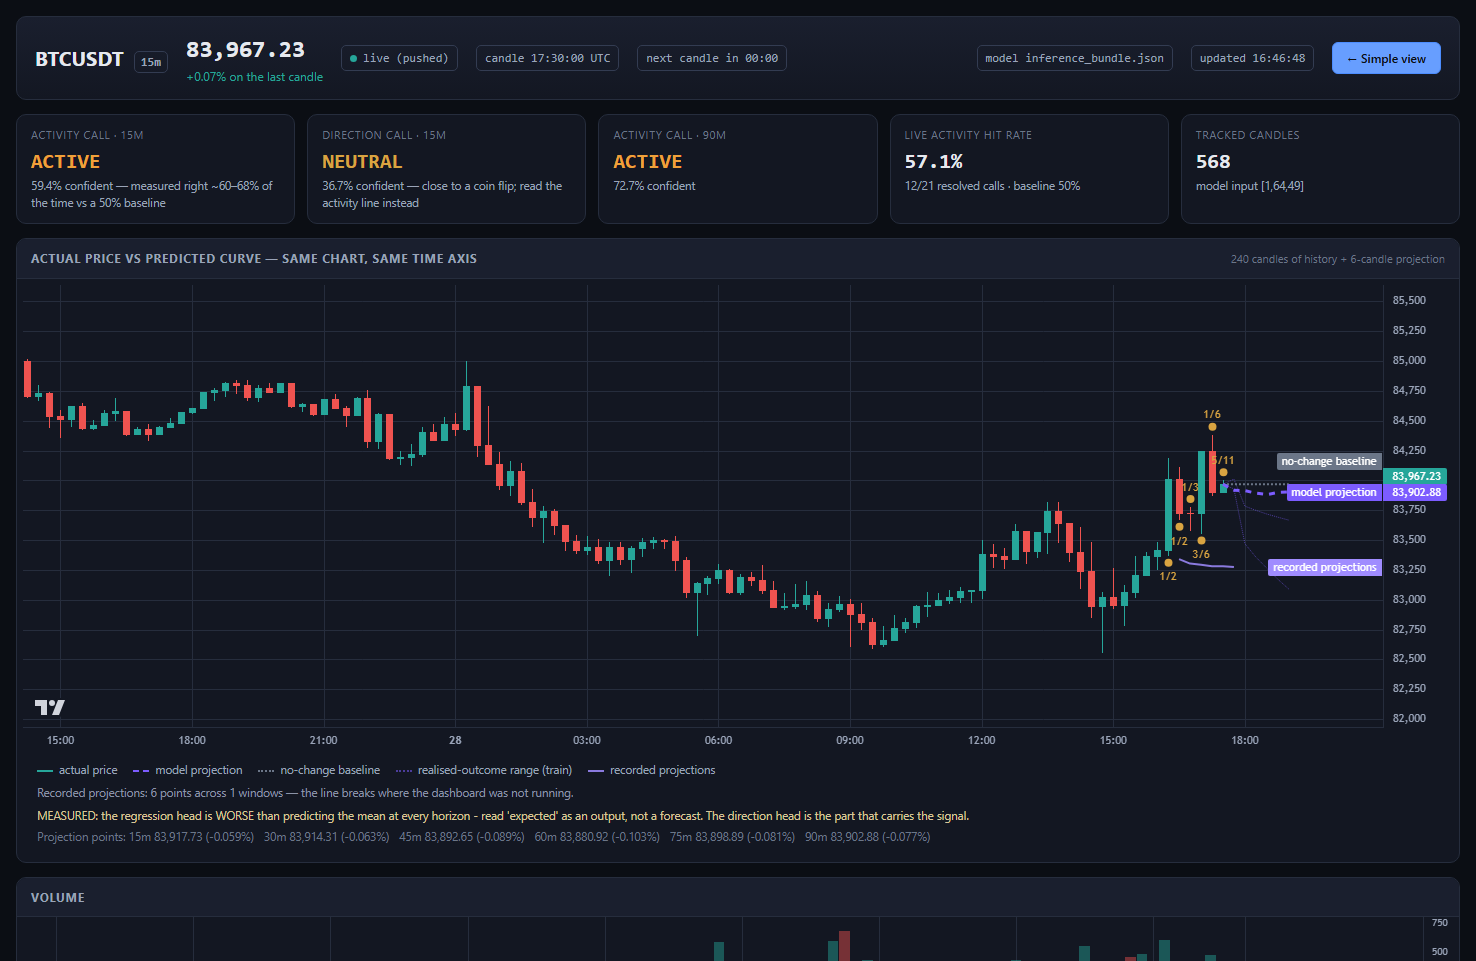

### T12_react_simple_view.png
99,858 bytes — 2026-10-07 22:16:49

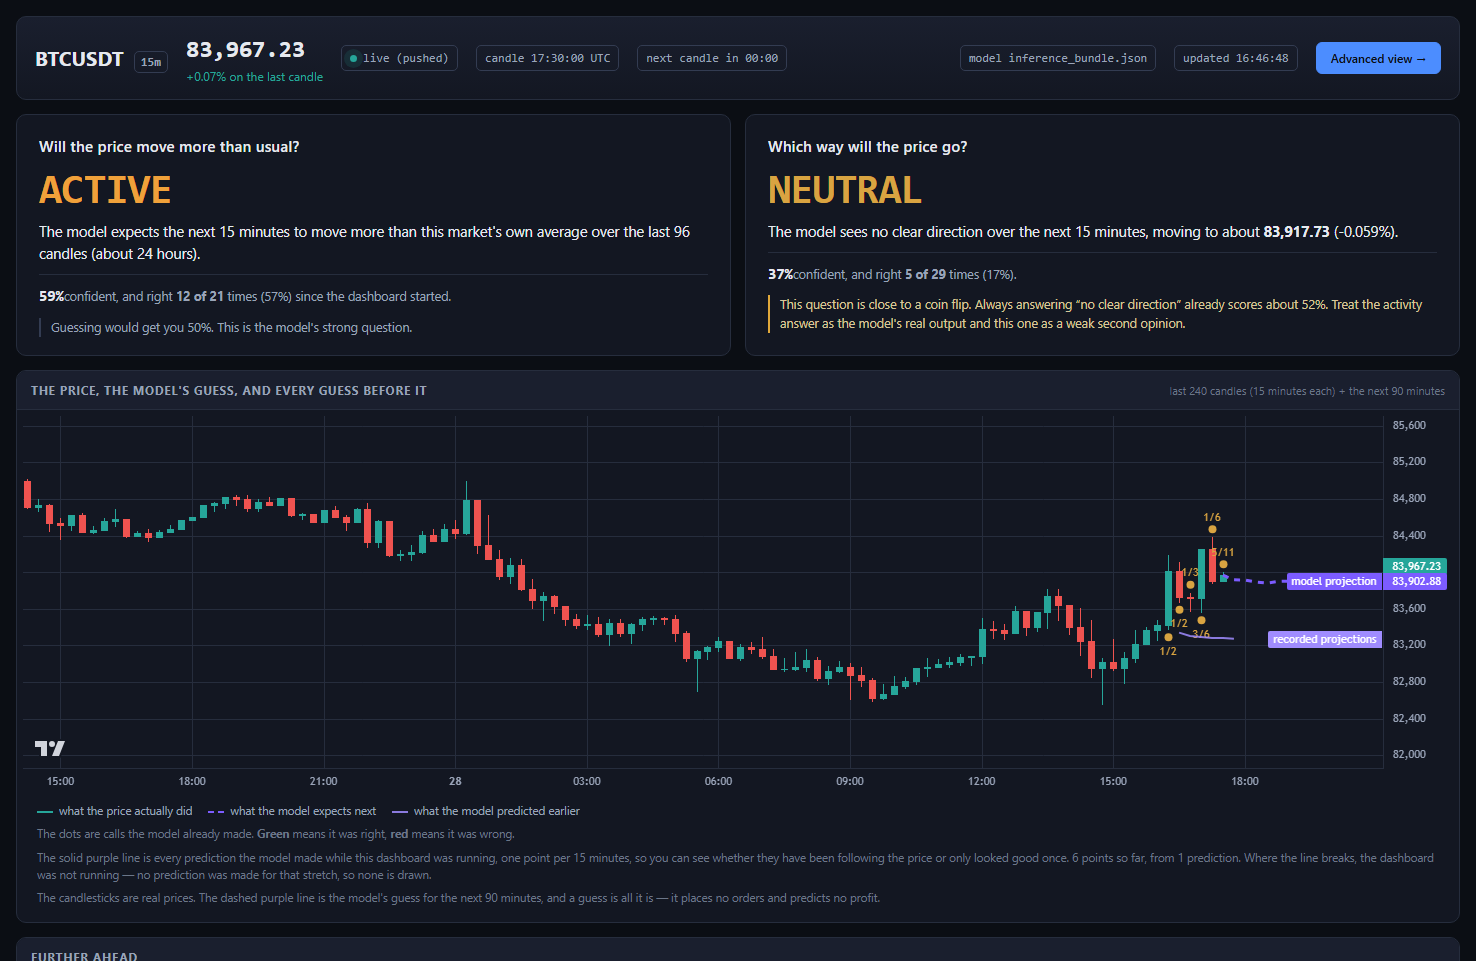

In [7]:
shots = results["evidence"]["screenshots"]
byname = sorted(Path(e["path"]).name for e in shots)
print(f"{len(shots)} evidence file(s) in tests/screenshots/ "
      f"({sum(e['bytes'] for e in shots):,} bytes)")
for name in byname:
    print("  ", name)

for png in sorted(_support.SCREENSHOTS_DIR.glob("*.png")):
    display(Markdown(f'### {png.name}\n{png.stat().st_size:,} bytes — '
                     f'{png.stat().st_mtime and __import__("datetime").datetime.fromtimestamp(png.stat().st_mtime).strftime("%Y-%m-%d %H:%M:%S")}'))
    display(Image(filename=str(png)))

## 7. Final summary

In [8]:
t = results["totals"]
print("=" * 78)
print("T01-T13 ACCEPTANCE RUN")
print("=" * 78)
print(f'  started        : {results["started"]}')
print(f'  finished       : {results["finished"]}')
print(f'  wall clock     : {results["duration_seconds"]:.1f}s')
print(f'  command        : {results["command"]}')
print(f'  pytest exit    : {results["exit_code"]}')
print()
print(f'  cases          : {t["cases_passed"]}/13 PASS, {t["cases_failed"]} FAIL, '
      f'{t["cases_blocked"]} BLOCKED, {t["cases_partial"]} PARTIAL')
print(f'  tests          : {t["n_tests"]} total, {t["passed"]} passed, '
      f'{t["failed"]} failed, {t["errors"]} errors, {t["skipped"]} skipped')
print()
for c in results["test_cases"]:
    print(f'  {c["id"]}  {c["status"]:<8} {c["n_tests"]:>2} test(s)  '
          f'{c["duration_seconds"]:6.2f}s  {c["title"][:60]}')
print()
print("  log        :", _support.RUN_LOG)
print("  results    :", _support.RESULTS_JSON)
print("  screenshots:", _support.SCREENSHOTS_DIR)
print()
print("  run again  : python tests/run_tests.py")
print("  tests only : pytest tests -v")

T01-T13 ACCEPTANCE RUN
  started        : 2026-10-07T16:45:45+00:00
  finished       : 2026-10-07T16:47:02+00:00
  wall clock     : 77.4s
  command        : pytest E:\_KDU\Academic\Semester 4\ai\GROUP AS\btc-trend-prediction\tests -v
  pytest exit    : 0

  cases          : 13/13 PASS, 0 FAIL, 0 BLOCKED, 0 PARTIAL
  tests          : 91 total, 91 passed, 0 failed, 0 errors, 0 skipped

  T01  PASS      3 test(s)    0.21s  Leakage - corrupt every row after row 2,000, recompute featu
  T02  PASS      4 test(s)    0.47s  Leakage - corrupt validation/test rows and refit the scaler;
  T03  PASS      6 test(s)    0.27s  Windows - every generated window checked for gap crossing (e
  T04  PASS      6 test(s)    0.46s  Split - chronological ordering and purge boundaries (train <
  T05  PASS      4 test(s)   19.98s  Audit - all 24 existing data-quality/audit checks pass (24/2
  T06  PASS     14 test(s)   16.67s  API - snapshot, candles, prediction, track-record and metric
  T07  PASS     18 test(s

## Notes

* **Nothing is mocked that is not an external dependency.** The API and
  dashboard cases run the project's real FastAPI app and real Renderer; the
  browser cases start a real `uvicorn` on an ephemeral loopback port and drive
  it with a real headless browser. Where a case cannot run at all — no `node`,
  no `web/dist`, no browser, no built dataset — it reports **BLOCKED** with the
  reason, and this notebook shows that reason rather than hiding it.
* **The production code was not modified to make these tests pass.** Where a
  test disagreed with the project, the test was wrong and was fixed.
* **The log and `results.json` are written by `tests/conftest.py`**, so a bare
  `pytest tests -v` produces them too. `tests/run_tests.py` adds the console
  transcript and the printed table.
* Screenshots and logs are written only inside `tests/`.
